# Customer review sentiment

In [37]:
import pandas as pd
import nltk
import string
import re

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [38]:
df=pd.read_csv('/home/ninelaps/uber-ml/data/csv/reviews.csv')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('omw-1.4')


[nltk_data] Downloading package punkt_tab to
[nltk_data]     /home/ninelaps/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/ninelaps/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/ninelaps/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /home/ninelaps/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package omw-1.4 to /home/ninelaps/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [39]:
stop_words = set(stopwords.words('english'))

# Preserve negation words for sentiment analysis
stop_words = stop_words - {'not', 'no', 'nor'}

lemmatizer = WordNetLemmatizer()

# Text cleaning function
def clean_text(text):

    # 1. Lowercasing
    text = text.lower()

    # 2. Tokenization
    tokens = word_tokenize(text)

    # 3. Punctuation removal
    tokens = [
        word for word in tokens
        if word not in string.punctuation
    ]

    # Remove remaining punctuation attached to words
    tokens = [
        ''.join(char for char in word if char not in string.punctuation)
        for word in tokens
    ]
    tokens = [word for word in tokens if word]

    # 4. Stop-word removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # 5. Lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word, pos='v')
        for word in tokens
    ]

    # Join tokens back into a sentence
    return ' '.join(cleaned_tokens)


# Apply cleaning to every review
df['cleaned_review'] = df['review_text'].apply(clean_text)

# Display original and cleaned reviews
print(df)

       review_id  order_id customer_id restaurant_id  rating  \
0      RV0000001  O0000002     C007734        R00440       5   
1      RV0000002  O0000003     C006407        R00244       4   
2      RV0000003  O0000004     C007317        R00496       4   
3      RV0000004  O0000010     C004491        R00135       3   
4      RV0000005  O0000012     C001590        R00180       5   
...          ...       ...         ...           ...     ...   
19077  RV0019078  O0049991     C001354        R00402       3   
19078  RV0019079  O0049993     C004690        R00080       5   
19079  RV0019080  O0049994     C001077        R00084       5   
19080  RV0019081  O0049995     C005251        R00146       5   
19081  RV0019082  O0049997     C006342        R00276       4   

                                             review_text sentiment_label  \
0      Really tasty Mediterranean. Will order again f...        positive   
1      Food arrived hot and packing was solid. Cynthi...        positive   
2  

In [ ]:
df = df.dropna(subset=['cleaned_review']).copy()
df = df[df['cleaned_review'].str.strip() != '']

# 2. Convert reviews into TF-IDF features
# Unigrams = single words
# Bigrams = two-word phrases
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=5000
)

tfidf_matrix = vectorizer.fit_transform(df['cleaned_review'])

print("Number of reviews:", tfidf_matrix.shape[0])
print("Number of TF-IDF features:", tfidf_matrix.shape[1])

# 3. Find important words and phrases
terms = vectorizer.get_feature_names_out()

# Average TF-IDF score for each feature
average_scores = tfidf_matrix.mean(axis=0).A1

important_terms = pd.DataFrame({
    'term': terms,
    'tfidf_score': average_scores
})

important_terms = important_terms.sort_values(
    'tfidf_score', ascending=False
)

print("\nTop 20 Important Words and Phrases:")
print(important_terms.head(20).to_string(index=False))

# 4. Find positive and negative keywords
df['sentiment_label'] = (
    df['sentiment_label'].astype(str).str.lower().str.strip()
)

# Check actual labels in your dataset
print("\nSentiment labels:")
print(df['sentiment_label'].value_counts())

# Adjust these values if your dataset uses different labels
positive_labels = ['positive', 'positive sentiment']
negative_labels = ['negative', 'negative sentiment']

positive_reviews = df[
    df['sentiment_label'].isin(positive_labels)
]

negative_reviews = df[
    df['sentiment_label'].isin(negative_labels)
]

def get_top_terms(reviews, top_n=20):
    if len(reviews) == 0:
        return pd.DataFrame(
            columns=['term', 'tfidf_score']
        )

    matrix = vectorizer.transform(reviews['cleaned_review'])
    scores = matrix.mean(axis=0).A1

    result = pd.DataFrame({
        'term': terms,
        'tfidf_score': scores
    })

    return result[result['tfidf_score'] > 0].sort_values(
        'tfidf_score', ascending=False
    ).head(top_n)

positive_keywords = get_top_terms(positive_reviews)
negative_keywords = get_top_terms(negative_reviews)

print("\nTop Positive Keywords and Phrases:")
print(positive_keywords.to_string(index=False))

print("\nTop Negative Keywords and Phrases:")
print(negative_keywords.to_string(index=False))

# 5. Save the results
important_terms.to_csv('/home/ninelaps/uber-ml/data/csv/important_tfidf_terms.csv', index=False)
positive_keywords.to_csv('/home/ninelaps/uber-ml/data/csv/positive_keywords.csv', index=False)
negative_keywords.to_csv('/home/ninelaps/uber-ml/data/csv/negative_keywords.csv', index=False)

print(vectorizer.get_feature_names_out())
print(tfidf_matrix.toarray())


Number of reviews: 19082
Number of TF-IDF features: 1888

Top 20 Important Words and Phrases:
            term  tfidf_score
        delivery     0.041702
            meal     0.039022
            time     0.038052
             app     0.037591
           price     0.037277
            size     0.036938
  generous price     0.036938
        generous     0.036938
   fast delivery     0.036938
delivery portion     0.036938
   size generous     0.036938
            fast     0.036938
    portion size     0.036938
         portion     0.036938
    accurate app     0.035183
            felt     0.035183
      fresh prep     0.035183
   felt accurate     0.035183
       prep time     0.035183
      everything     0.035183

Sentiment labels:
sentiment_label
positive    14132
neutral      3809
negative     1141
Name: count, dtype: int64

Top Positive Keywords and Phrases:
            term  tfidf_score
   size generous     0.049877
delivery portion     0.049877
   fast delivery     0.049877
     

Number of reviews: 15273

Sentiment distribution:
sentiment_label
positive    14132
negative     1141
Name: count, dtype: int64

Model Evaluation
----------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0

Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       228
    positive       1.00      1.00      1.00      2827

    accuracy                           1.00      3055
   macro avg       1.00      1.00      1.00      3055
weighted avg       1.00      1.00      1.00      3055



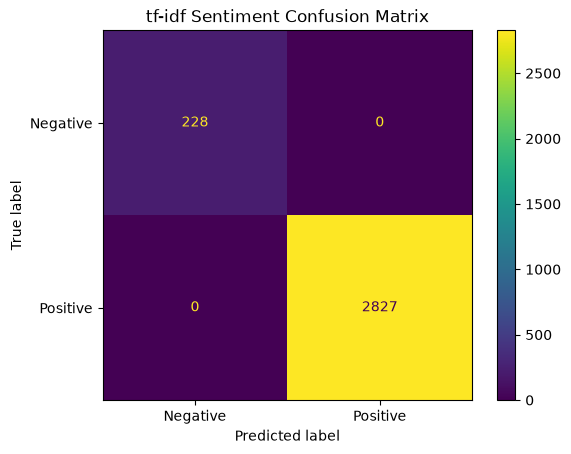

In [ ]:
model_df = df[['cleaned_review', 'sentiment_label']].dropna().copy()

model_df['sentiment_label'] = (
    model_df['sentiment_label'].astype(str).str.lower().str.strip()
)

# Keep only positive and negative reviews
model_df = model_df[
    model_df['sentiment_label'].isin(['positive', 'negative'])
]

X = model_df['cleaned_review']
y = model_df['sentiment_label']

print("Number of reviews:", len(model_df))
print("\nSentiment distribution:")
print(y.value_counts())

# 2. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Create TF-IDF + Naive Bayes pipeline
model = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), max_features=5000)),
    ('classifier', MultinomialNB())
])

# 4. Train the model
model.fit(X_train, y_train)

# 5. Predict sentiment
y_pred = model.predict(X_test)

# 6. Evaluate the model
print("\nModel Evaluation")
print("----------------")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("Precision:", round(
    precision_score(y_test, y_pred, pos_label='positive', zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred, pos_label='positive', zero_division=0), 4
))

print("F1-score:", round(
    f1_score(y_test, y_pred, pos_label='positive', zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# 7. Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=['negative', 'positive']
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

display.plot()
plt.title("Naive Bayes - Sentiment Confusion Matrix")
plt.show()


Naive Bayes Accuracy: 1.0
VADER Accuracy: 0.8422

Naive Bayes Classification Report:
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00       228
    positive       1.00      1.00      1.00      2827

    accuracy                           1.00      3055
   macro avg       1.00      1.00      1.00      3055
weighted avg       1.00      1.00      1.00      3055


VADER Classification Report:
              precision    recall  f1-score   support

    negative       0.82      0.69      0.75       228
     neutral       0.00      0.00      0.00         0
    positive       0.99      0.85      0.92      2827

    accuracy                           0.84      3055
   macro avg       0.60      0.52      0.56      3055
weighted avg       0.97      0.84      0.90      3055



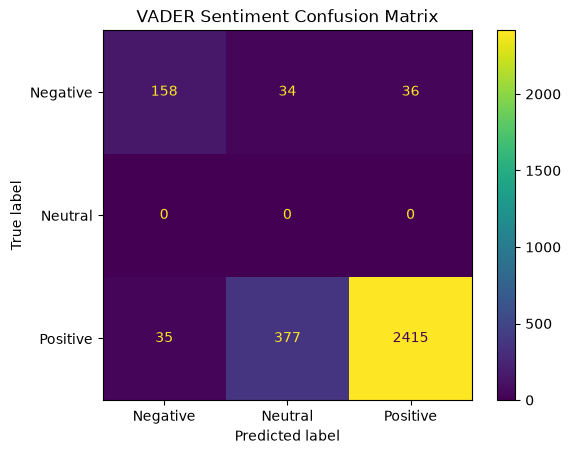


Sample Comparison:
                                                             review_text actual_sentiment naive_bayes    vader  agree
           Loved the meal. Tip well earned — smooth handoff at the door.         positive    positive positive   True
               Uber One perks made this a great value. Highly recommend.         positive    positive positive   True
   Really tasty Healthy / Bowls. Will order again from Sunset Diner San.         positive    positive positive   True
   Really tasty Burgers. Will order again from Fire Cantina Burgers New.         positive    positive negative  False
           Really tasty American. Will order again from Blue Garden New.         positive    positive  neutral  False
               Uber One perks made this a great value. Highly recommend.         positive    positive positive   True
               Everything was fresh. Prep time felt accurate in the app.         positive    positive positive   True
Really tasty Healthy / Bowls. Will o

In [42]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Initialize VADER
analyzer = SentimentIntensityAnalyzer()

# 2. VADER sentiment prediction function
def vader_sentiment(text):
    scores = analyzer.polarity_scores(str(text))
    compound = scores['compound']

    if compound >= 0.05:
        sentiment = 'positive'
    elif compound <= -0.05:
        sentiment = 'negative'
    else:
        sentiment = 'neutral'

    return sentiment

# 3. Apply VADER to the original review text
# Use original text to preserve emojis, slang, and punctuation
original_reviews = df.loc[X_test.index, 'review_text'].fillna('')

vader_predictions = original_reviews.apply(vader_sentiment)

# 4. Get traditional ML predictions from Part 3
nb_predictions = model.predict(X_test)

# 5. Compare accuracy on the same test reviews
print("Naive Bayes Accuracy:",
      round(accuracy_score(y_test, nb_predictions), 4))

print("VADER Accuracy:",
      round(accuracy_score(y_test, vader_predictions), 4))

# 6. Classification reports
print("\nNaive Bayes Classification Report:")
print(classification_report(
    y_test,
    nb_predictions,
    labels=['negative', 'positive'],
    zero_division=0
))

print("\nVADER Classification Report:")
print(classification_report(
    y_test,
    vader_predictions,
    labels=['negative', 'neutral', 'positive'],
    zero_division=0
))

# 7. Confusion matrix for VADER
cm_vader = confusion_matrix(
    y_test,
    vader_predictions,
    labels=['negative', 'neutral', 'positive']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_vader,
    display_labels=['Negative', 'Neutral', 'Positive']
)

disp.plot()
plt.title("VADER Sentiment Confusion Matrix")
plt.show()

# 8. Compare predictions review by review
comparison = pd.DataFrame({
    'review_text': original_reviews,
    'actual_sentiment': y_test,
    'naive_bayes': nb_predictions,
    'vader': vader_predictions
})

comparison['agree'] = (
    comparison['naive_bayes'] == comparison['vader']
)

print("\nSample Comparison:")
print(comparison.head(10).to_string(index=False))

print("\nAgreement between models:",
      round(comparison['agree'].mean() * 100, 2), "%")


In [43]:
from sklearn.feature_extraction.text import CountVectorizer

# Select negative reviews
negative_reviews = df.loc[
    df['sentiment_label'].astype(str).str.lower().str.strip()
    == 'negative',
    'cleaned_review'
].dropna()

# Find frequent words and two-word phrases
complaint_vectorizer = CountVectorizer(
    ngram_range=(1, 2),
    max_features=100
)

complaint_matrix = complaint_vectorizer.fit_transform(
    negative_reviews
)

# Count occurrences
complaint_counts = complaint_matrix.sum(axis=0).A1

complaints = pd.DataFrame({
    'theme_or_phrase':
        complaint_vectorizer.get_feature_names_out(),
    'count': complaint_counts
}).sort_values('count', ascending=False)

print("Top customer complaints/themes:")
print(complaints.head(20).to_string(index=False))

complaints.to_csv('/home/ninelaps/uber-ml/data/csv/top_customer_complaints.csv', index=False)

Top customer complaints/themes:
theme_or_phrase  count
          order    576
            not    377
        kitchen    215
         dinner    212
   show reorder    212
           show    212
 reorder dinner    212
        reorder    212
     order show    212
          wrong    212
    wrong order    212
           wait    212
    dinner wait    212
     far longer    193
         backup    193
      come back    193
    driver seem    193
           back    193
traffic kitchen    193
           seem    193
